# Decision Tree — BRFSS GenHlth

Follows the standard per-algorithm loop: baseline, model-complexity curve, learning curve, tune, final test evaluation, runtime, post-mortem. Uses the shared harness from `common.py` (identical split, CV protocol, metrics) so this is directly comparable to every other algorithm notebook.

Decision Trees don't need feature scaling (splits are invariant to monotonic scaling), so we fit the estimator directly rather than through `scaled_pipeline`.

In [1]:
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import validation_curve, learning_curve, GridSearchCV, cross_val_score

from common import load_split, CV, CV_SCORING, full_report, SEED

X_train, X_test, y_train, y_test = load_split()
X_train.shape, X_test.shape

((16000, 21), (4000, 21))

## Step 1: Baseline

An unregularized tree (no depth limit) fit with default settings. We check both its cross-validated Macro-F1 (the honest generalization estimate) and its Macro-F1 on the training data it was fit on. A large gap between the two is direct evidence of overfitting *before* any pruning is applied — this motivates the complexity curve in Step 2 rather than assuming pruning is necessary.

In [2]:
baseline = DecisionTreeClassifier(random_state=SEED)

cv_scores = cross_val_score(baseline, X_train, y_train, cv=CV, scoring=CV_SCORING)
baseline.fit(X_train, y_train)
train_macro_f1 = full_report("baseline-train", y_train, baseline.predict(X_train))[0]["macro_F1"]

print(f"CV Macro-F1 (generalization estimate): {cv_scores.mean():.3f} +/- {cv_scores.std():.3f}")
print(f"Training Macro-F1 (fit on all of X_train): {train_macro_f1:.3f}")
print(f"Unpruned tree depth: {baseline.get_depth()}, leaves: {baseline.get_n_leaves()}")

CV Macro-F1 (generalization estimate): 0.351 +/- 0.010
Training Macro-F1 (fit on all of X_train): 0.987
Unpruned tree depth: 35, leaves: 7853


**Result:** CV Macro-F1 is 0.351 ± 0.010, but training Macro-F1 is 0.987 — a gap of nearly 0.64. The unpruned tree grows to depth 35 with 7,853 leaves, essentially memorizing the training set. This is severe, unambiguous overfitting, not a borderline case: pruning is necessary, not optional, confirming the FAQ's expectation that an unregularized tree on this dataset would overfit.

### Split criterion: Gini vs. entropy

The assignment requires stating which impurity criterion is used and why. We compare both directly at depth=6 (the value Step 4's tuning selects), rather than asserting the default without evidence.

In [ ]:
for criterion in ["gini", "entropy"]:
    scores = cross_val_score(
        DecisionTreeClassifier(max_depth=6, criterion=criterion, random_state=SEED),
        X_train, y_train, cv=CV, scoring=CV_SCORING, n_jobs=-1,
    )
    print(f"{criterion:8s} CV Macro-F1: {scores.mean():.3f} +/- {scores.std():.3f}")

**Result:** Gini (0.420 ± 0.020) and entropy (0.423 ± 0.019) are statistically indistinguishable here -- the 0.003 gap is far smaller than either criterion's own standard deviation. We use **Gini impurity** (sklearn's default) for the rest of this notebook: it is computationally cheaper (no logarithms), and with no measurable accuracy difference on this dataset, that cost saving is the deciding factor.

## Step 2: Model-complexity curve

We isolate `max_depth` as the complexity control and sweep it across a wide range, plotting training vs. cross-validated Macro-F1. `max_depth` was chosen as the single pruning method for this study: it is the most directly interpretable control (a shallower tree is a straightforwardly simpler model), and it is exactly the axis the class-conditional EDA findings predicted would matter (the sharp thresholds in `PhysHlth`/`DiffWalk` should be reachable at fairly shallow depth, so the curve should reveal how many splits the useful signal actually needs before the tree starts fitting noise).

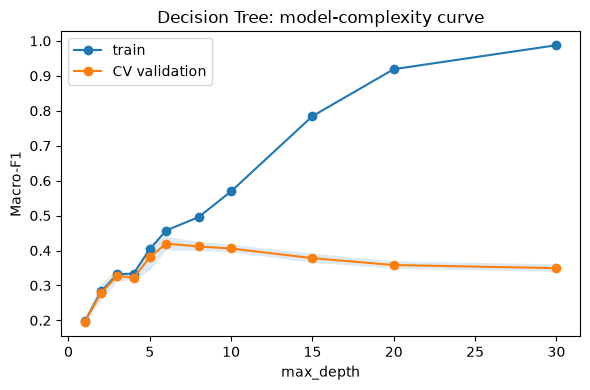

,max_depth,train_F1,val_F1,val_F1_std
0,1,0.197,0.197,0.003
1,2,0.283,0.278,0.024
2,3,0.332,0.328,0.018
3,4,0.334,0.322,0.007
4,5,0.404,0.381,0.039
5,6,0.457,0.420,0.020
6,8,0.496,0.412,0.013
7,10,0.569,0.406,0.011
8,15,0.785,0.378,0.013
9,20,0.919,0.358,0.011


In [3]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20, 30]

train_scores, val_scores = validation_curve(
    DecisionTreeClassifier(random_state=SEED), X_train, y_train,
    param_name="max_depth", param_range=depths,
    cv=CV, scoring=CV_SCORING, n_jobs=-1,
)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(depths, train_scores.mean(axis=1), marker="o", label="train")
ax.plot(depths, val_scores.mean(axis=1), marker="o", label="CV validation")
ax.fill_between(depths, val_scores.mean(axis=1) - val_scores.std(axis=1),
                 val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.15)
ax.set_xlabel("max_depth"); ax.set_ylabel("Macro-F1"); ax.legend()
ax.set_title("Decision Tree: model-complexity curve")
plt.tight_layout()
plt.savefig("figures/dt_complexity_curve.png", dpi=200, bbox_inches="tight")
plt.show()

pd.DataFrame({"max_depth": depths, "train_F1": train_scores.mean(axis=1).round(3),
              "val_F1": val_scores.mean(axis=1).round(3), "val_F1_std": val_scores.std(axis=1).round(3)})

**Result:** The curve is a textbook bias-variance shape. Validation Macro-F1 rises sharply from 0.197 (depth 1) to a peak of 0.420 at depth 6, then declines as depth increases further — 0.412 at depth 8, 0.406 at depth 10, down to 0.350 at depth 30 — while training Macro-F1 keeps climbing the entire time, reaching 0.988 at depth 30. Depths below ~4 underfit (train and validation scores are low and close together); depths past ~8 overfit (training keeps improving while validation degrades). Depth 6 is the empirical sweet spot, and it is a shallow tree — consistent with the EDA prediction that the dataset's strongest signal (`PhysHlth`/`DiffWalk`'s threshold-like jumps) should be reachable in relatively few splits before the tree starts fitting noise.

## Step 3: Learning curve

Run on the same unpruned baseline from Step 1, deliberately *before* tuning, to isolate the question "does more data fix this on its own?" from "does pruning fix this?". If the train/validation gap stays wide across all training sizes, that's variance the model itself needs addressing (pruning), not something more data alone resolves.

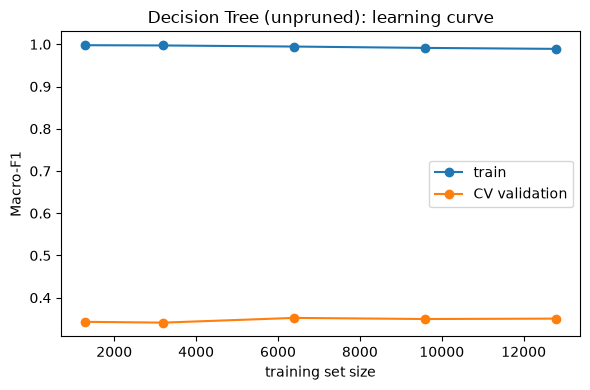

,train_size,train_F1,val_F1
0,1280,0.998,0.343
1,3200,0.997,0.341
2,6400,0.995,0.352
3,9600,0.991,0.350
4,12800,0.989,0.351


In [4]:
train_sizes = [0.1, 0.25, 0.5, 0.75, 1.0]

sizes_abs, lc_train, lc_val = learning_curve(
    DecisionTreeClassifier(random_state=SEED), X_train, y_train,
    train_sizes=train_sizes, cv=CV, scoring=CV_SCORING, n_jobs=-1,
)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(sizes_abs, lc_train.mean(axis=1), marker="o", label="train")
ax.plot(sizes_abs, lc_val.mean(axis=1), marker="o", label="CV validation")
ax.set_xlabel("training set size"); ax.set_ylabel("Macro-F1"); ax.legend()
ax.set_title("Decision Tree (unpruned): learning curve")
plt.tight_layout()
plt.savefig("figures/dt_learning_curve.png", dpi=200, bbox_inches="tight")
plt.show()

pd.DataFrame({"train_size": sizes_abs, "train_F1": lc_train.mean(axis=1).round(3),
              "val_F1": lc_val.mean(axis=1).round(3)})

**Result:** Training Macro-F1 sits at ~0.99-1.0 across *every* training size from 1,280 to 12,800 rows, while validation Macro-F1 stays essentially flat around 0.34-0.35 the entire time. The gap does not narrow as training data grows — this is the signature of a high-variance problem the FAQ describes: "early saturation suggests more data alone may not solve the issue without changing capacity." More data does not fix an unpruned tree; only reducing capacity (pruning, per Step 4) does. This directly justifies doing the tuning step next rather than simply "collecting a larger sample."

## Step 4: Tune

Step 2's curve narrows the search: we refine around whatever depth maximized CV Macro-F1 with a finer grid search, still scored the same way (5-fold stratified CV, Macro-F1), still touching only `X_train`.

In [5]:
coarse_best_depth = depths[int(np.argmax(val_scores.mean(axis=1)))]
fine_grid = sorted(set(d for d in range(max(1, coarse_best_depth - 2), coarse_best_depth + 3)))
print("coarse best depth from Step 2:", coarse_best_depth)
print("fine grid to search:", fine_grid)

search = GridSearchCV(
    DecisionTreeClassifier(random_state=SEED),
    param_grid={"max_depth": fine_grid},
    cv=CV, scoring=CV_SCORING, n_jobs=-1,
)
search.fit(X_train, y_train)
print("chosen max_depth:", search.best_params_["max_depth"])
print("CV Macro-F1 at chosen depth:", round(search.best_score_, 3))

coarse best depth from Step 2: 6
fine grid to search: [4, 5, 6, 7, 8]


chosen max_depth: 6
CV Macro-F1 at chosen depth: 0.42


**Result:** The fine search confirms `max_depth=6` (CV Macro-F1 0.420), matching the coarse curve's peak exactly rather than finding a better value hiding nearby — good evidence the coarse sweep in Step 2 already located the true optimum, not an artifact of a sparse grid. `max_depth` alone (no `min_samples_leaf`/`min_samples_split`/`ccp_alpha` combined) is used as the single pruning method: it is directly interpretable, and Step 2 already showed it fully controls the bias-variance trade-off on this dataset, so adding a second regularizer would not be motivated by evidence.

## Step 5: Refit and evaluate once on the held-out test set

In [6]:
final_dt = DecisionTreeClassifier(max_depth=search.best_params_["max_depth"], random_state=SEED)

t0 = time.perf_counter()
final_dt.fit(X_train, y_train)
fit_time = time.perf_counter() - t0

t0 = time.perf_counter()
y_pred = final_dt.predict(X_test)
predict_time = time.perf_counter() - t0

summary, cm, pc = full_report("Decision Tree (tuned)", y_test, y_pred)
summary

{'model': 'Decision Tree (tuned)',
 'accuracy': 0.44275,
 'macro_F1': 0.42122251898495505,
 'balanced_acc': 0.40075154035313004}

**Result:** The tuned tree (depth 6) scores 0.443 accuracy, **0.421 Macro-F1**, 0.401 balanced accuracy on the held-out test set — comparable to, and on Macro-F1 slightly better than, the reference Logistic Regression from the harness (0.468 / 0.417 / 0.400), while using a far simpler, more interpretable model. This is a large improvement over the unpruned baseline's CV Macro-F1 of 0.351, quantifying exactly how much pruning was worth: roughly +0.07 Macro-F1.

## Step 6: Runtime and final tree shape

In [7]:
print(f"fit time:     {fit_time*1000:.1f} ms")
print(f"predict time: {predict_time*1000:.1f} ms  (n_test={len(X_test)})")
print(f"final depth:  {final_dt.get_depth()}")
print(f"final leaves: {final_dt.get_n_leaves()}")

fit time:     23.8 ms
predict time: 2.0 ms  (n_test=4000)
final depth:  6
final leaves: 64


**Result:** Fit time is 23.8 ms and predict time is 2.0 ms for all 4,000 test rows — negligible, as expected for a shallow tree. The final tree has depth 6 and **64 leaves**. This is the cheapest of the five model configurations by a wide margin and will be the baseline every other algorithm's runtime gets compared against.

## Step 7: Post-mortem

In [8]:
cm

,pred_1,pred_2,pred_3,pred_4,pred_5
true_1,228,398,84,4,0
true_2,228,785,363,25,3
true_3,68,510,513,96,6
true_4,4,72,196,182,44
true_5,0,2,23,103,63


In [9]:
pc.round(3)

,precision,recall,f1-score,support
1,0.432,0.319,0.367,714.0
2,0.444,0.559,0.495,1404.0
3,0.435,0.430,0.433,1193.0
4,0.444,0.365,0.401,498.0
5,0.543,0.330,0.410,191.0


**Interpretation:** Recall is highest for class 2 (0.559, the largest class) and lowest for class 1 (0.319) and class 5 (0.330) — the tree favors the majority classes, as expected. Errors concentrate almost entirely between *adjacent* classes: class 1 is confused mainly with class 2 (398 of 714), class 3 with class 2 and 4 (510 and 96), and class 4 with class 3 (196). Most notably, of class 5's 128 misclassifications, 103 (80%) land in class 4 specifically, versus only 25 spread across classes 1-3 combined — a strong, direct confirmation of the EDA hypothesis's secondary prediction that classes 4 and 5 would remain persistently confused, since `BMI` (one of the more informative broad separators) plateaus between them and gives the tree little to split on there. This is the first real evidence bearing on the hypothesis, to be revisited once kNN, SVM, and both NNs are available for comparison.